# Part 2 - Data quality and the bank-quarter panel

BFT65B final report, walkthrough notebook. Every number below is read from `reports/` or recomputed live by the same scripts the README lists. Seed: `config.SEED = 42`.

In [1]:
import json, os, subprocess, sys
from pathlib import Path

import pandas as pd
import polars as pl
from IPython.display import Image, Markdown, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
import config as C

pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 80)
R = ROOT / "reports"
print("project root:", ROOT, "| python", sys.version.split()[0], "| polars", pl.__version__, "| seed", C.SEED)


def run(script, *args, tail=25):
    """Run one pipeline script exactly as the README does, and show the end of its output."""
    t = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", env={**os.environ, "PYTHONUTF8": "1"})
    lines = (t.stdout + t.stderr).strip().splitlines()
    print("\n".join(lines[-tail:]))
    print(f"\n>>> {script} {' '.join(args)} exited with {t.returncode}")
    assert t.returncode == 0, "step failed"


def csv(name, n=None):
    df = pd.read_csv(R / name)
    display(df if n is None else df.head(n))


def fig(name, width=820):
    display(Image(filename=str(R / name), width=width))

project root: D:\Final BigData | python 3.15.2 | polars 2.1.0 | seed 42


**Goal.** An automated data-quality report, a rule for every problem found, and a clean panel that
separates failures from other exits and is point-in-time correct.

In [2]:
run('src/p2_build_panel.py')

shape: (12, 5)
┌───────┬──────────────────────────────────┬──────────────┬────────────────┬───────────┐
│ rule  ┆ what                             ┆ rows_changed ┆ banks_affected ┆ rows_left │
│ ---   ┆ ---                              ┆ ---          ┆ ---            ┆ ---       │
│ str   ┆ str                              ┆ i64          ┆ i64            ┆ i64       │
╞═══════╪══════════════════════════════════╪══════════════╪════════════════╪═══════════╡
│ start ┆ bronze financials                ┆ 0            ┆ 0              ┆ 1682616   │
│ R1    ┆ no Institutions record           ┆ 10996        ┆ 235            ┆ 1671620   │
│ R2    ┆ EQ null, no capital reported     ┆ 3806         ┆ 42             ┆ 1667814   │
│ R3    ┆ report dated on or after failure ┆ 1095         ┆ 268            ┆ 1666719   │
│ R4    ┆ RBCRWAJ == 0 means not reported  ┆ 462176       ┆ 20785          ┆ 1666719   │
│ R4    ┆ RBC1AAJ == 0 means not reported  ┆ 74378        ┆ 3815           ┆ 1666719   │
│ R5  

In [3]:
run('src/p2_quality.py', tail=12)

| LNCI     | 2020-06-30 | 10.085         | 3.349    | 28.4       |
| OTHBFHLB | 2001-03-31 | 0.0            | -6.848   | 25.9       |
| COREDEP  | 2010-03-31 | 76.846         | 10.543   | 21.1       |
| LNRE     | 2020-06-30 | 44.349         | -4.952   | 14.1       |
| ORE      | 2009-03-31 | 0.127          | 0.043    | 10.0       |
| NAASSET  | 2009-03-31 | 0.71           | 0.127    | 7.9        |
| RBC1AAJ  | 2020-06-30 | 10.312         | -0.612   | 7.8        |
| CHBAL    | 2022-06-30 | 7.452          | -3.029   | 6.8        |
| LIAB     | 2022-03-31 | 90.621         | 0.893    | 6.7        |
| ROE      | 1992-03-31 | 12.68          | 2.54     | 6.7        |
| EQ       | 2022-03-31 | 9.383          | -0.892   | 6.6        |
| NIMY     | 2022-03-31 | 3.024          | -0.233   | 6.0        |

>>> src/p2_quality.py  exited with 0


### Cleaning waterfall: what each rule changed

In [4]:
csv('p2_waterfall.csv')

,rule,what,rows_changed,banks_affected,rows_left
0,start,bronze financials,0,0,1682616
1,R1,no Institutions record,10996,235,1671620
2,R2,"EQ null, no capital reported",3806,42,1667814
3,R3,report dated on or after failure,1095,268,1666719
4,R4,RBCRWAJ == 0 means not reported,462176,20785,1666719
5,R4,RBC1AAJ == 0 means not reported,74378,3815,1666719
6,R5,"LNLSDEPR undefined, DEP == 0",2798,312,1666719
7,R5,"NCLNLSR undefined, LNLSGR == 0",9545,714,1666719
8,R5,"NTLNLSR undefined, LNLSGR == 0",9545,714,1666719
9,R6,"ROE meaningless, EQ <= 0",14604,2825,1666719


### Issue register (problem, evidence, handling)

In [5]:
csv('p2_issue_register.csv')

,dimension,issue,rows,banks,period,handling
0,uniqueness,"Duplicate (CERT, REPDTE)",0.0,0.0,-,Build stops if any appear
1,uniqueness,Same CERT with two in-scope FAILURE records,0.0,3.0,1986-1989,First date is the event; panel stops there
2,uniqueness,Failures rows with no CERT,488.0,NaN,before 1984,Out of scope; panel starts 1984
3,completeness,P3ASSET null: field starts in 2001,971925.0,22718.0,1984-2000,Keep null; Part 4 cannot use it across eras without care
4,completeness,"OTHBFHLB null, mostly commercial banks before 2001",826539.0,18872.0,1984-2026,Keep null; never impute before fitting
5,completeness,"P9ASSET null, mostly thrifts before 1990",77731.0,4180.0,1984-1996,Keep null; missingness tracks charter type
6,completeness,RBCRWAJ == 0: not reported before 1990Q1,419414.0,20479.0,1984-1989,R4 zero to null
7,completeness,RBCRWAJ == 0 from 2020 with leverage ratio present (CBLR election),45423.0,2604.0,2020-2026,R4 zero to null; f_cblr flag
8,completeness,"RBC1AAJ == 0: not reported, mostly thrifts before 1990",79496.0,3880.0,1984-2026,R4 zero to null
9,completeness,EQ null: no capital (branches of foreign banks and similar),4148.0,45.0,1984-2026,R2 remove row; none of these banks failed


### Exit classes: failure against merger and other exits

In [6]:
csv('p2_exit_health.csv')

,_exit_class,banks,first_year,last_year,median_asset,median_eq_ta_pct,eq_nonpositive_pct,median_roa,median_nc_ta_pct
0,merger,15339,1984,2026,104086.0,8.96,0.8,0.82,0.51
1,active_at_end,4242,2026,2026,386818.0,10.56,0.0,1.23,0.31
2,failure,2837,1984,2026,65781.0,0.02,49.7,-4.41,7.34
3,distress_no_failure_record,623,1984,2009,102478.0,-14.52,94.1,-5.45,7.06
4,voluntary_closing,487,1984,2026,55893.0,14.09,2.5,0.17,0.11
5,assisted_merger,242,1984,1989,125098.0,-13.14,93.0,-5.58,8.70
6,other_or_unknown,14,1989,2014,11933.0,50.78,0.0,0.60,0.03
7,active_late_report,2,2026,2026,191800.0,11.51,0.0,1.32,0.05
8,failure_after_scope,2,2026,2026,38337.0,3.33,0.0,-4.53,4.99


### Automated tests of the panel and the label (the script exits non-zero on any failure)

In [7]:
run('src/p2_checks.py')

PASS  key unique  1,666,719 rows
PASS  no report on or after failure  
PASS  y matches independent recomputation  0 differences; 10,860 positives
PASS  y null exactly after last model quarter  2025-06-30
PASS  only failed banks have y = 1  
PASS  at most 4 positive rows per bank  
PASS  failures without a positive row are only those with no earlier report  2,858 events, 2,837 labelled, 21 with no report before failure
PASS  rows removed by R1 and R2 belong to banks that never failed  0 failure records hit
PASS  mergers are never failures  15,339 merged banks
PASS  assisted banks that never failed are y = 0  
PASS  last report before failure agrees with FDIC's QBFASSET  98.9% within 5%
PASS  four quarterly flows sum to the December year-to-date value  404,636 bank-years
PASS  no label-side or snapshot field in the point-in-time list  []
PASS  known case: Silicon Valley  last report 2022-12-31, failed 2023-03-10, y = 1 on 4 rows
PASS  known case: First Republic  last report 2023-03-31, f

In [8]:
csv('p2_checks.csv')

,test,passed,detail
0,key unique,True,"1,666,719 rows"
1,no report on or after failure,True,NaN
2,y matches independent recomputation,True,"0 differences; 10,860 positives"
3,y null exactly after last model quarter,True,2025-06-30
4,only failed banks have y = 1,True,NaN
5,at most 4 positive rows per bank,True,NaN
6,failures without a positive row are only those with no earlier report,True,"2,858 events, 2,837 labelled, 21 with no report before failure"
7,rows removed by R1 and R2 belong to banks that never failed,True,0 failure records hit
8,mergers are never failures,True,"15,339 merged banks"
9,assisted banks that never failed are y = 0,True,NaN


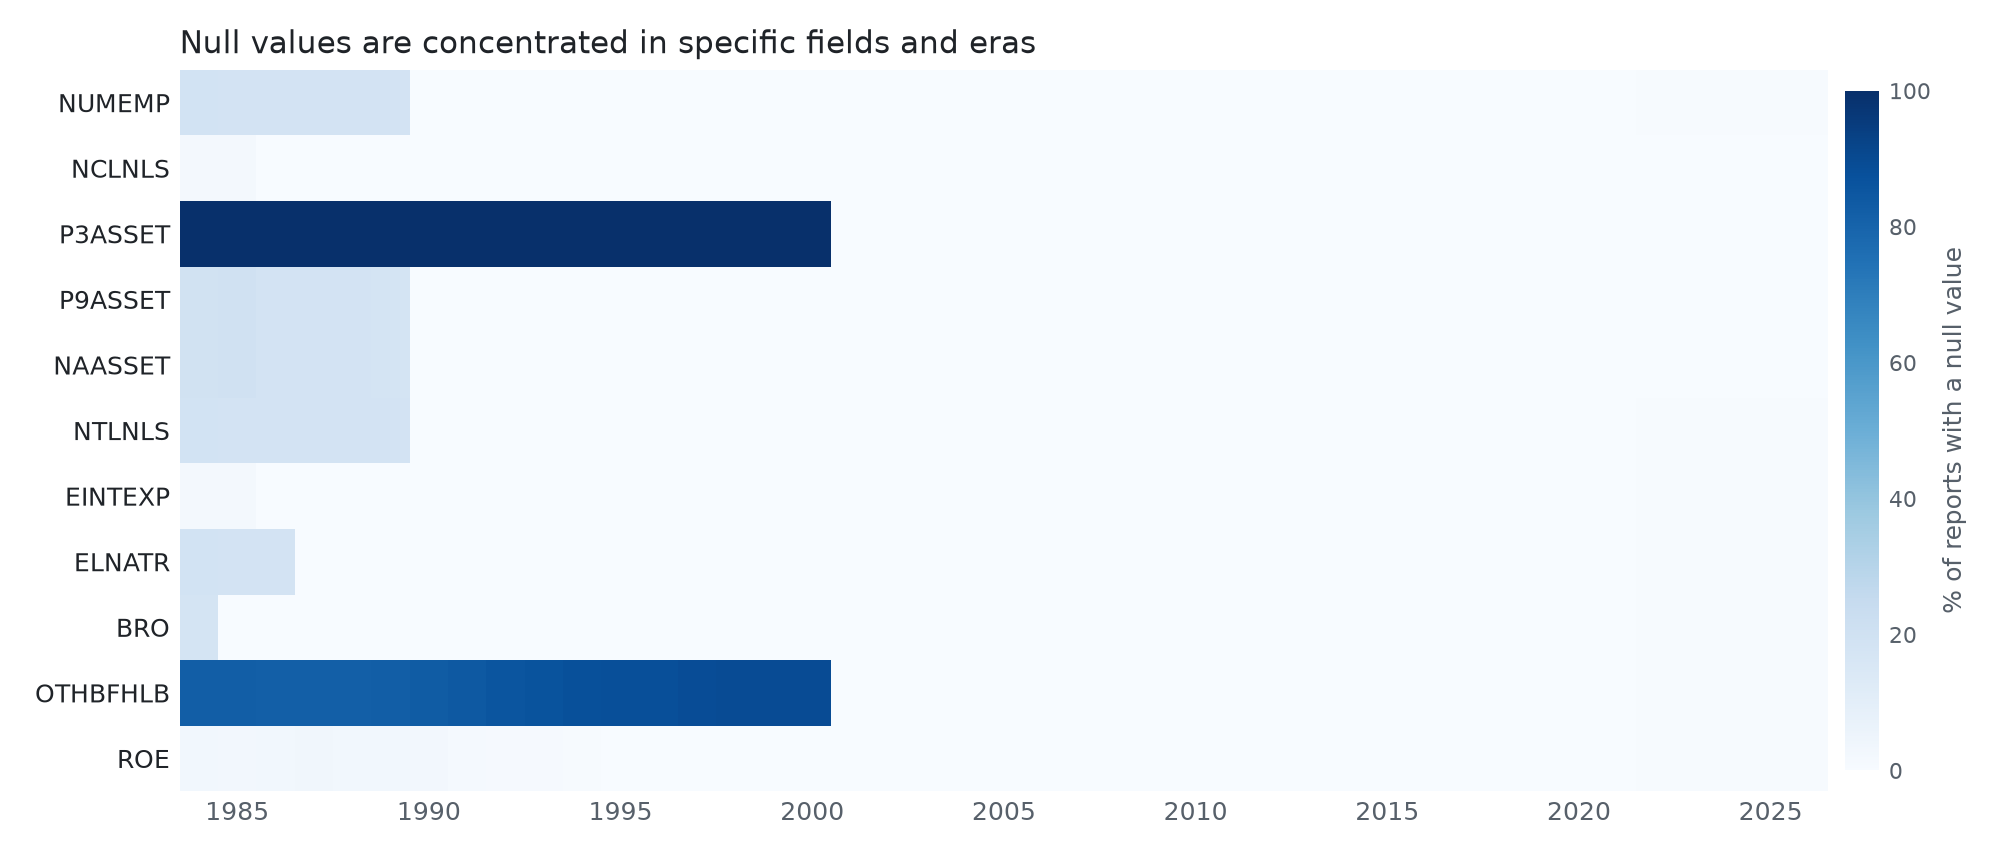

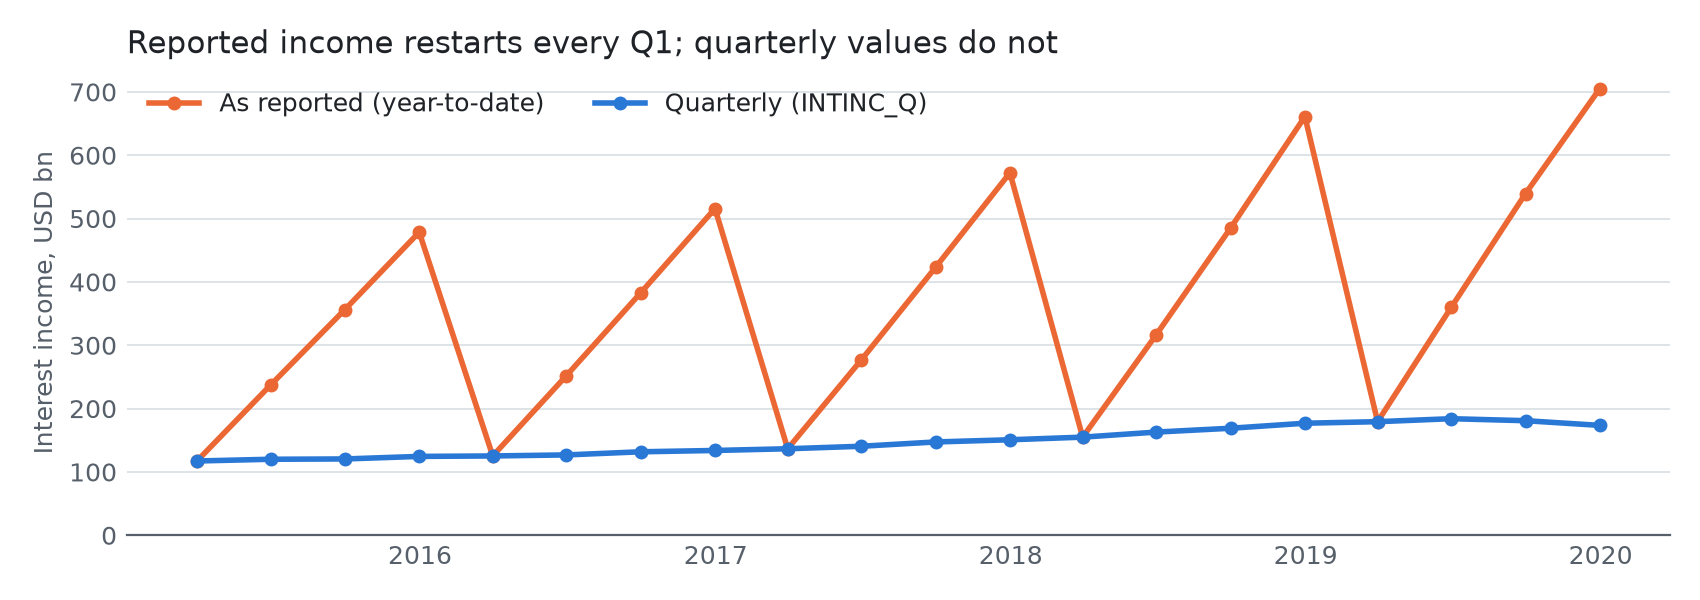

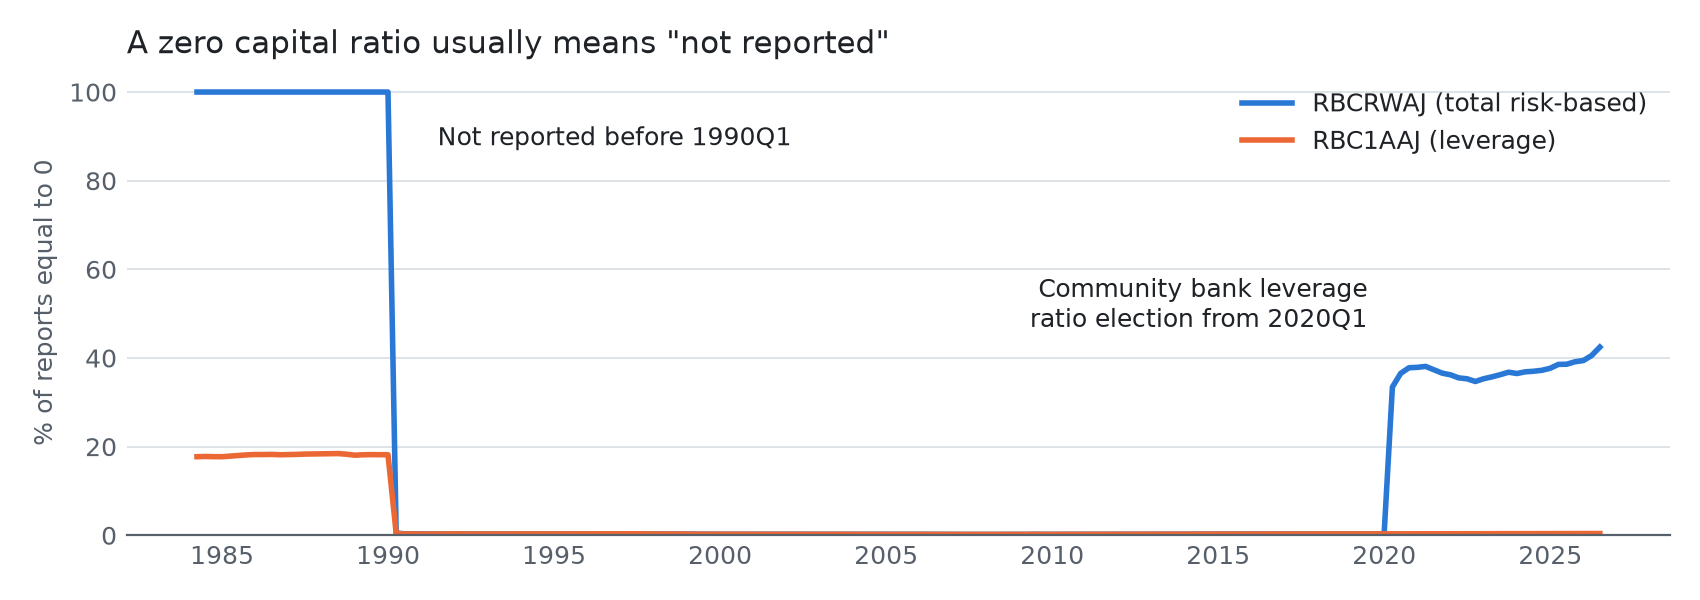

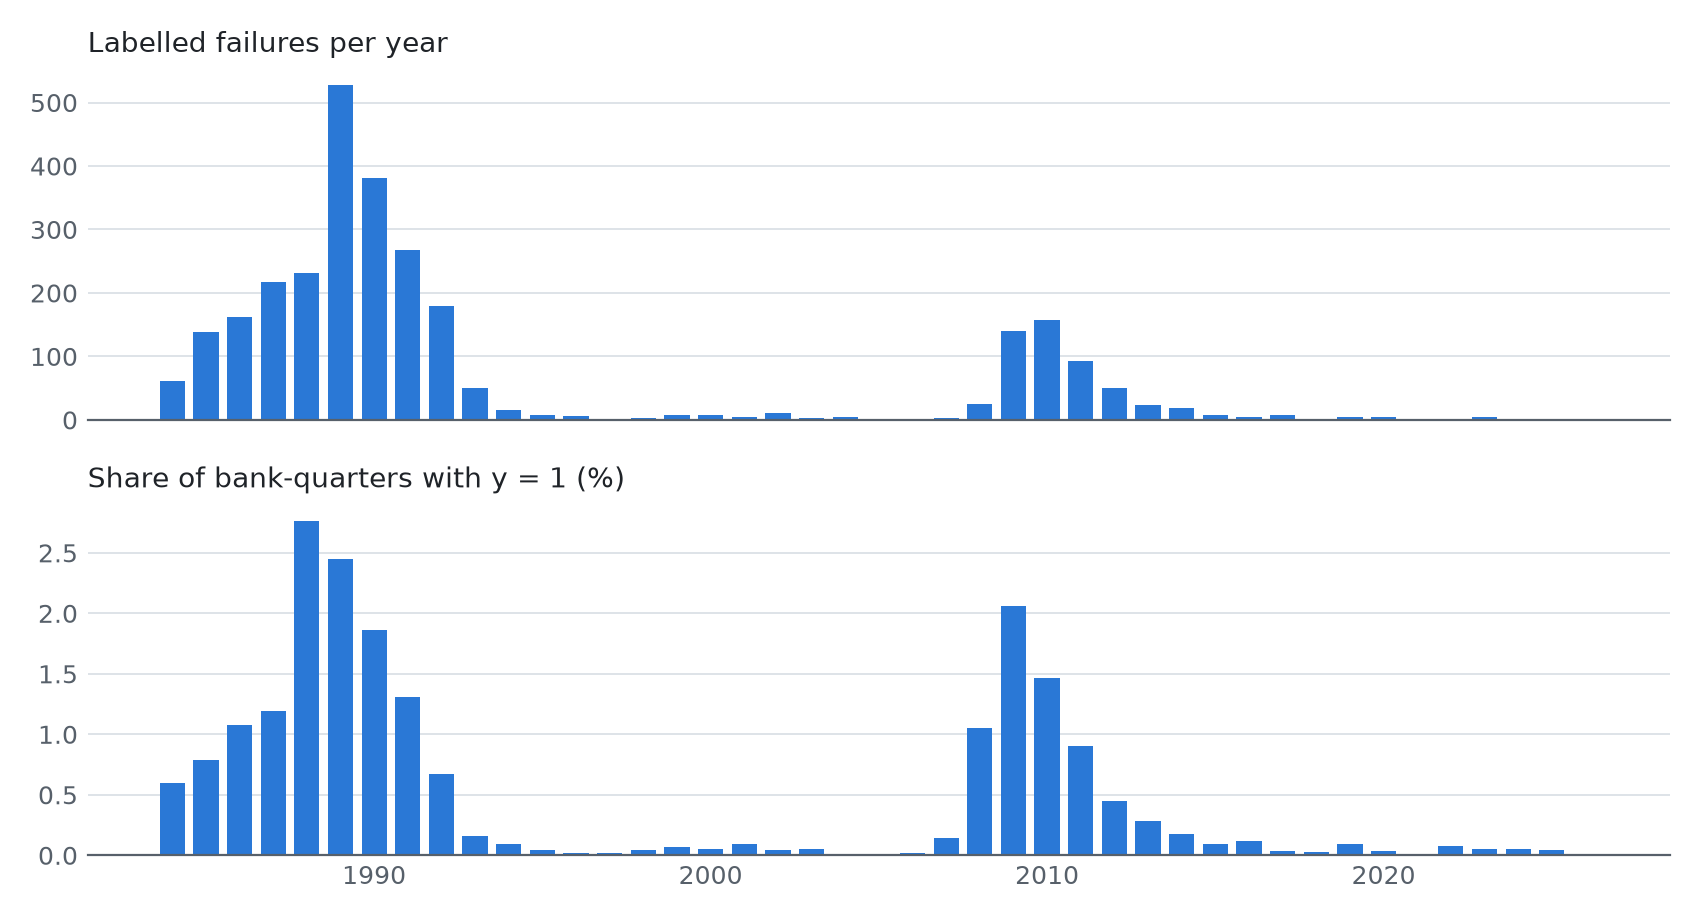

In [9]:
fig('fig_p2_missing.png'); fig('fig_p2_ytd.png'); fig('fig_p2_capital_zero.png'); fig('fig_p2_failures.png')